# **Artificial Intelligence & Machine Learning (ST1511) CA2 Part B:**
### **Name: Cayden Sim**
### **Student ID: P2510893**
### **Class: DAAA/FT/1B/01**


---

## **Background Overview:**
- 397 days of data on energy consumption was collected. With each date representing the first day of each month from 1990 to 2022.
- The data includes:
    - Date
    - Gas Consumption (tons)
    - Electricity Consumption (MWh)
    - Water Consumption (tons)

## **Planned Workflow:**
-  ### Oveerall Workflow includes:
    - Data Exploration (EDA)
        - Understand data distribution, patterns and relationships
        - Identify potential outliers/anomalies
    - Preprocessing
        - Handle any missing values
        - Feature Engineering
    - Model Building and Implementation
        - Implement various models from Statsmodel library
    - Evaluation
        -  Model Comparison
            - Compare results across multiple forecasting models
            - Determine most suitable model that achieves the best results
    - Hyperparameter Tuning:
        - After finalising the model to use, conduct hyperparameter tuning in order to get the most optimal parameters that result in the most optimal results.


- ### **Libraries Used:**
    - **Data Manipulation & Numerical Operation**
        - pandas
        - numpy
    - **Machine Learning:**
        - statsmodel
        - scikitlearn
    - **Data Visualization**
        - matplotlib
        - Seaborn


## **Ultimate End Goal:**
The ultimate goal of this project is to forecast the total energy consumption (gas, electricity & water) for the next 60 months via training time series models




---
## **Step 1:** Importing Necessary Libraries and Modules

- Importing the required libraries as well as modules that are going to be used in this project.

In [30]:
# %pip install pmdarima

- Auto-ARIMA requires the external `pmdarima` library, which is installed separately to enable automated hyperparameter selection for ARIMA-based models.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima


- Libraries added include:
    - pandas
    - numpy
    - matplotlib
    - seaborn
- **pandas** and **numpy** are used for data handling and analysis.
- **matplotlib** and **seaborn** are used to display visuals and graphs.

--- 
## **Step 2:** Loading Dataset's CSV File

- Import the downloaded dataset from the file explorer.

In [32]:
energy_df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA2/CA2 Datasets/CA2-Energy-Consumption-Data.csv")

- Energy Consumption Data dataset is imported via pandas' **`.read_csv()`** method.
- Dataset is stored into a variable **`'energy_df'`**.

--- 
## **Step 3:** Exploratory Data Analysis **(EDA)**

- ### **Planned Overview**: 
    - Showcase dataset's information.

    - Check for missing data in columns. 

    - Identifying major outliers that can affect the output of the machine.

    - Visualize data spread with graphs.

    - Identifying any relationships between columns via pairplot/correlation heatmap

    - **Numerical Columns**: 

    - **Categorical Columns**: 

In [33]:
print("Here is a quick look at the DataFrame:")
energy_df

Here is a quick look at the DataFrame:


,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4
...,...,...,...,...
392,1/9/2022,27.7,986.2,513.3
393,1/10/2022,31.8,936.1,373.1
394,1/11/2022,31.0,973.4,343.9
395,1/12/2022,32.4,1147.2,348.3


- Here is how the DataFrame of energy consumption data looks like.

In [34]:
print("Here is the shape of the DataFrame: ", energy_df.shape)
energy_df.info()

Here is the shape of the DataFrame:  (397, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB


- Using the **`.shape`** attribute and printing it shows that the customer dataset has **397 rows** and **4 columns**.
- Using the **`.info()`** method on the DataFrame prints its information.
    - From the output, it is shown that all rows are **`non-null`**, indicating that there are no empty data cells.
    - **`dtype`** shows the types of data in each column.

In [35]:
print("DataFrame Description:")
energy_df.describe()

DataFrame Description:


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.000000,397.000000,397.000000
mean,23.785139,888.472544,484.953652
std,4.903452,153.877594,133.908863
min,11.600000,553.200000,44.400000
25%,20.200000,771.100000,384.400000
50%,23.500000,897.800000,487.400000
75%,27.900000,1005.200000,580.200000
max,46.000000,1294.000000,811.000000


- The **`describe()`** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

In [36]:
energy_df.isnull().sum()

DATE                             0
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64

- Using the pandas' **'.isnull()'** method together with the **'.sum()'** method, it computes the total number of empty values within each column.
- The output above shows that all columns **'.isnull().sum()'** equate to **0**, indicating that there are no missing values in each column.

---
## **Step 3.5 - Continutinuation of EDA:** Plotting Visuals (KIV Seasonal Decomposition)

- Some visuals will be plotted for better visualization and analysis of the original features.
- These visuals represents the relationship of each feature with another.

### **Mini Conversion Step:** Converting Data Column to Datetime Format **(Pre-Preprocessing)**
- Before we plot the visuals, convert the date column into a datetime format and set the index.
- This ensures that the dataset is treated as a proper time series.

In [37]:
energy_df['DATE'] = pd.to_datetime(energy_df['DATE'], format ='%d/%m/%Y')
energy_df = energy_df.sort_values('DATE').set_index('DATE')


energy_df

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4
...,...,...,...
2022-09-01,27.7,986.2,513.3
2022-10-01,31.8,936.1,373.1
2022-11-01,31.0,973.4,343.9


- Use pandas' '.to_datetime()' function to convert the dates in the DATE column into the datetime format. 
- After that, use .sort_values() and .set_index() and place 'DATE' inside the parenthesis.
- This ensures that the dates are ordered chronologically.
- This allows for easier graph plotting in the EDA portion.

**Not Preprocessing

## **Visual Representation 1: Histogram**

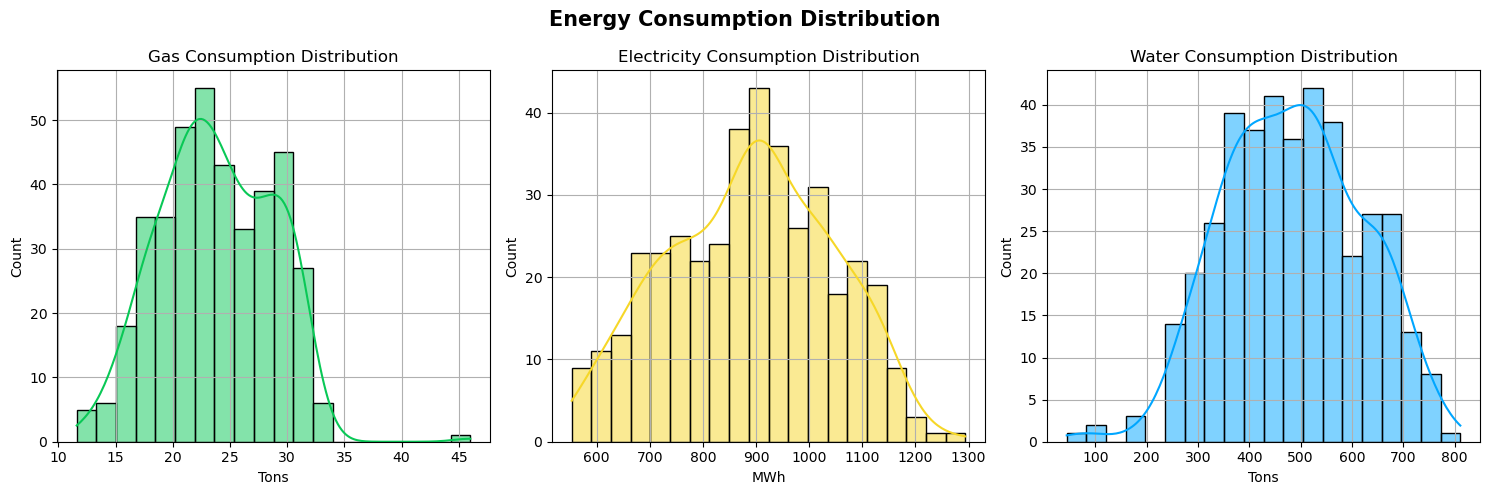

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(energy_df['Gas Consumption (tons)'], bins=20, ax=axes[0], kde=True, color="#09C856")
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.histplot(energy_df['Electricity Consumption (MWh)'], bins=20, ax=axes[1], kde=True, color="#F6D728")
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.histplot(energy_df['Water Consumption (tons)'], bins=20, ax=axes[2], kde=True, color="#00A6FF")
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
- The subplots of histograms illustrate the distribution of energy consumption for gas, electricity and water respectively, highlighting the differences in spread and skewness that was observed in the line chart.

- Skewness:
    - Gas consumption displays a right-skewed distribution, with most observations being concentrated between 20 to 30 tons. and a small number of higher value observation that extend the right tail like the 45 ton indicator on the far right.
    
    - Electricity consumption shows a more moderate right skew but resembles a normally distributed graph due to the exhibition of an almost symmetry-like shape between the left and right sides of the graph as well as its peak being in the centre of the data distribution.
        - Majority of the data is clustered around 800 to 1000 MWh, while there are fewer observations that have higher consumption above 1100Mwh as well as some observations that have a lower consumption than 800 MWh.
    
    - Water consumption exhibits a more left-skewed distribution, with more observations being on the right side of the graph, ranging from about 400 to 700 tons, with fewer observations on the left side that have a lower consumption than 300 tons.
        - Shows that lower water consumption is less frequent but still present.

    - The presence of right-skewness in gas and electricity consumption suggests that mean values may be influenced by higher consumption periods and vice versa for water consumption.

## **Visual Representation 2:** Boxplot

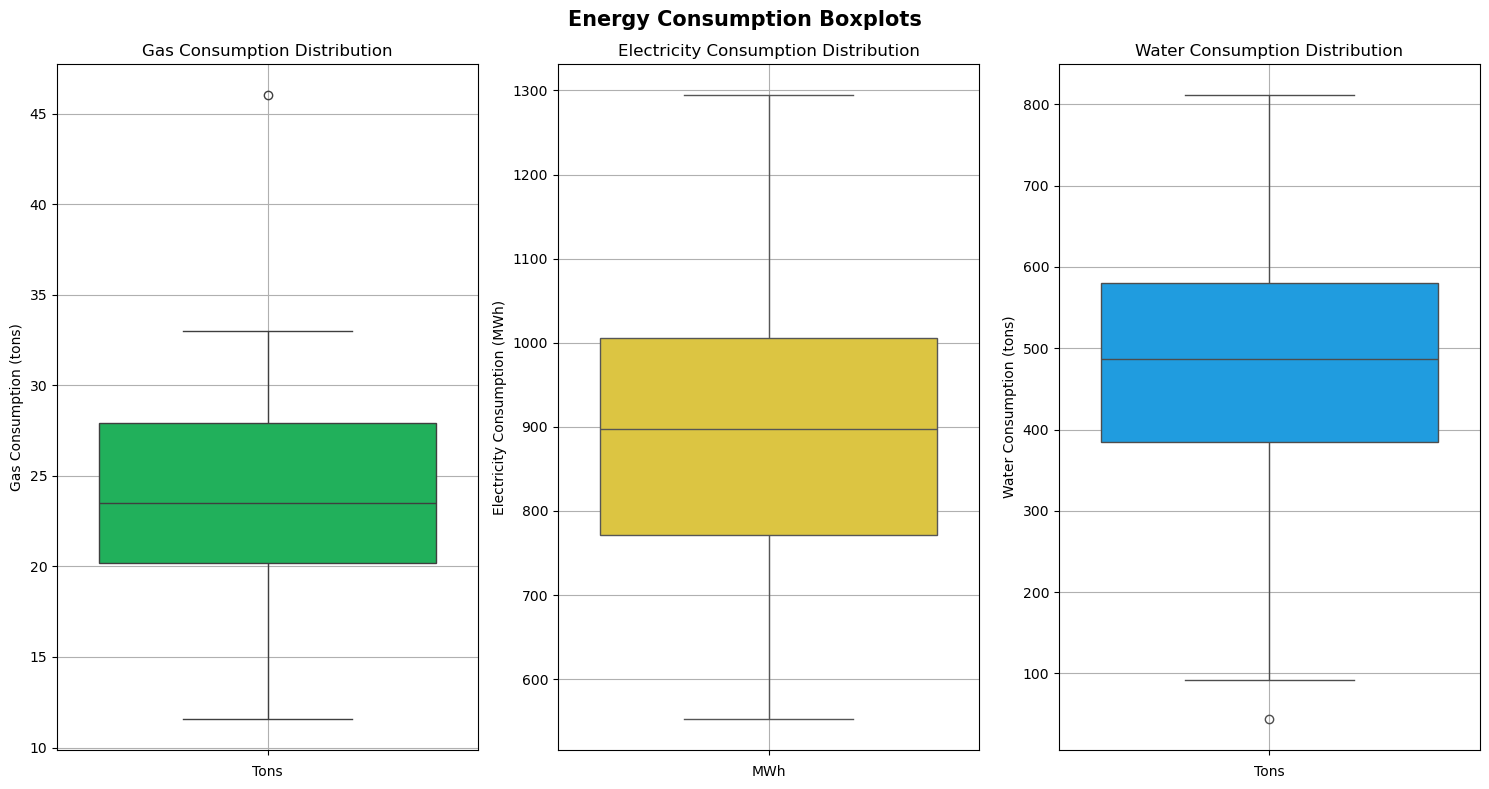

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

sns.boxplot(y=energy_df['Gas Consumption (tons)'], ax=axes[0], color='#09C856')
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.boxplot(y=energy_df['Electricity Consumption (MWh)'], ax=axes[1], color='#F6D728')
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.boxplot(y=energy_df['Water Consumption (tons)'], ax=axes[2], color='#00A6FF')
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Boxplots', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
These boxplots provide additional insights about the features that were not covered by the histograms.

- ### **Gas:** 
    - The median of gas consumption is closer to Q1 than it is to Q3, indicating that more data is concentrated on the lower side.
    - There is also an outlier at >45 tons, approximately 46-47 tons. Because of this outlier, it extends the right tail, causing the mean to be higher than the median, resulting in a right skew.

- ### **Electricity:**
    - Median is near the centre of the box, almost symmetrical.
    - Exhibits a wider interquartile range, illustrating a higher variability of the data.
    - The whiskers are relatively almost balanced, with the right tail being a little longer, hence it results in the moderate right-skewness of the distribution.
    - There are also no extreme outliers.
    - Indicates that electricity consumption is quite stable with minimal fluctuations, supporting the line chart.

- ### **Water:**
    - Median is slightly closer to Q3 than Q1, indicating that more data is concentrated on the upper side of the distribution.
    - The lower whisker/tail is longer than the upper one, with an anomaly on the lower side, <100 tons.
    - The presence of the anomaly on the lower bound brings the mean down, making it smaller than the median, resulting in a left skew.

- Overall, the spread of electricity and water consumption are much wider than that of gas consumption. Suggesting that the consumption of electricity and water is much wider and spread out, convering a larger numerical range than gas consumption.
    - Showing that there is a greater variance in these 2 energy sources due to the many diverse way they could be used.

## **Visual Representation 3: Decomposition Plot:**

<Figure size 1200x800 with 0 Axes>

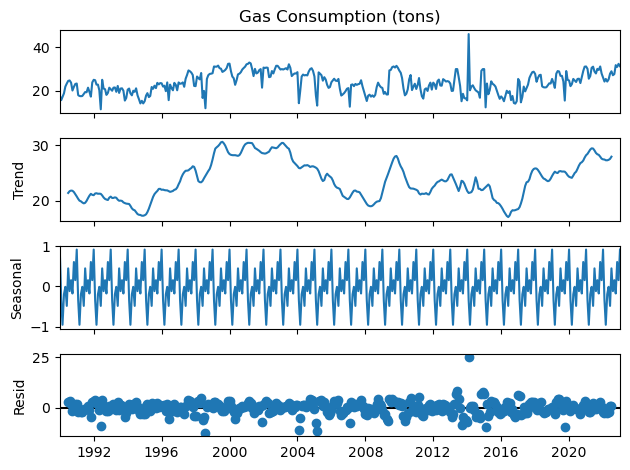

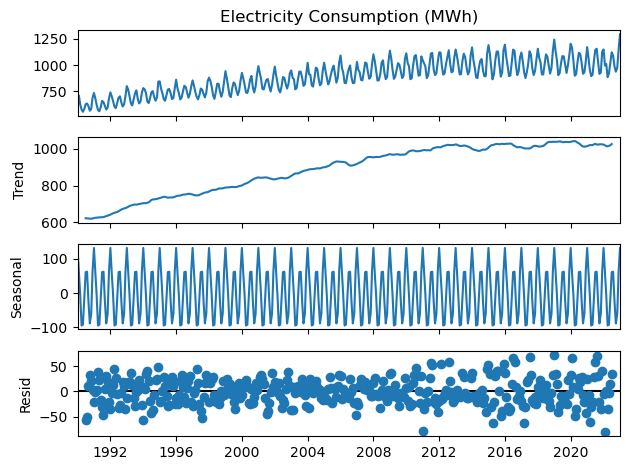

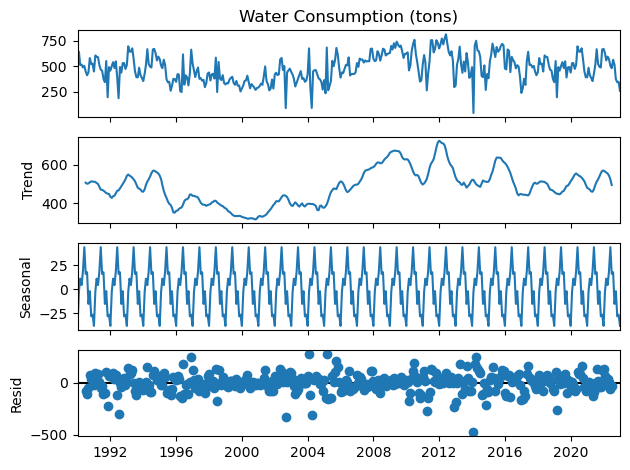

In [40]:
gas_results = seasonal_decompose(energy_df['Gas Consumption (tons)'], model='additive', period=12)
plt.figure(figsize=(12, 8))
gas_results.plot()
plt.show()


electricity_results = seasonal_decompose(energy_df['Electricity Consumption (MWh)'], model='additive', period=12)
electricity_results.plot()
plt.show()

water_results = seasonal_decompose(energy_df['Water Consumption (tons)'], model='additive', period=12)
water_results.plot()
plt.show()





### **Key Insights (Seasonal Decomposition):**

 The seasonal decomposition plots separate each energy series into observed, trend, seasonal, and residual components, providing deeper insight into their underlying structure.

- **Gas consumption:**
    - The trend component shows a gradual upward movement with moderate fluctuations, indicating a slow but steady increase in long-term usage. The seasonal component exhibits a stable and repeating annual pattern, while the residuals capture short-term irregular variations, including a notable spike corresponding to an unusually high consumption period.

- **Electricity consumption:**
    - Displays a strong and consistent upward trend, confirming long-term growth in electricity demand. Its seasonal component is highly regular and pronounced, indicating a clear yearly cycle. The residuals show moderate variability, suggesting that most systematic patterns are well explained by the trend and seasonal components.

- **Water consumption:**
    - Shows a more irregular trend pattern, with periods of increase followed by decline, reflecting changing long-term usage behaviour. The seasonal component remains relatively stable across years, while the residuals exhibit higher variability and occasional extreme deviations, indicating greater short-term unpredictability.

Overall, the decomposition confirms that all three series contain both trend and seasonal components, supporting the use of additive seasonal models. The presence of strong seasonality and long-term trends further justifies the application of SARIMA models with internal differencing for forecasting.

---
## **Step 4:** Preprocessing and Feature Engineering
- Check stationarity of all 3 energy types via **`Augmented Dickey Fuller`** (ADF) Test.

- Assuming the status quo/null hypothesis is that the 3 energy consumption types are non-stationary and the alternative hypothesis is that the 3 energy consumptions types are stationary.

- If the resulting **`p-value`** is **`>0.05`**, we **`do not reject`** the **`null hypothesis`** and hence the consumption types are **`non-stationary`**.
    - If **`non-stationary`**, have to **`conduct differencing`** then re-run ADF test.

- If resuling **`p-value`** is **`<0.05`**, then **`reject`** the **`null hypothesis`** and hence the energy consumptions types are **`stationary`**.
    - **`Differencing`** is **`not required`**.

## **Step 4.1:** Checking for Stationarity
In this part, the stationarity of the consumption of the 3 energy sources will be checked via the visual test (plotting graphs), and later confirmed via the **`Augmented Dickey Fuller (ADF)`** Test.

### **Visual Test:**
- The visual test aims to justify the stationarity of the 3 energy sources' consumption, so that we roughly know which sources to perform differencing later on.

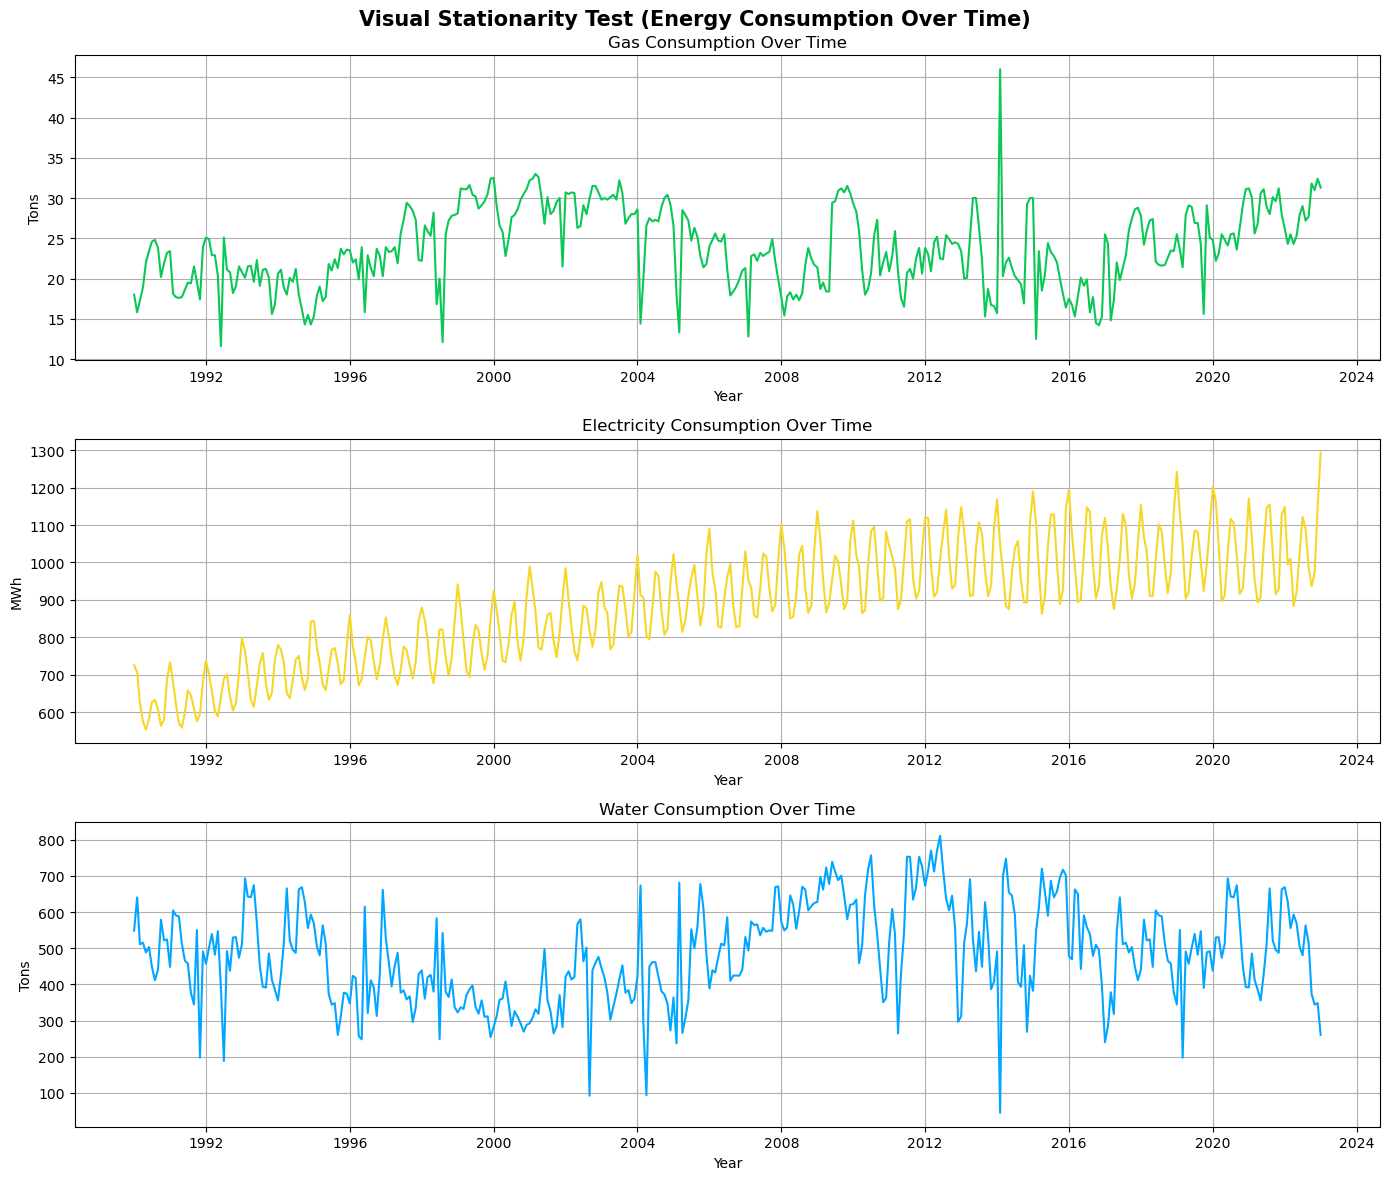

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(energy_df.index, energy_df['Gas Consumption (tons)'], color='#09C856')
axes[0].set_title('Gas Consumption Over Time')
axes[0].set_ylabel('Tons')
axes[0].set_xlabel('Year')
axes[0].grid(True)

axes[1].plot(energy_df.index, energy_df['Electricity Consumption (MWh)'], color='#F6D728')
axes[1].set_title('Electricity Consumption Over Time')
axes[1].set_ylabel('MWh')
axes[1].set_xlabel('Year')
axes[1].grid(True)

axes[2].plot(energy_df.index, energy_df['Water Consumption (tons)'], color='#00A6FF')
axes[2].set_title('Water Consumption Over Time')
axes[2].set_ylabel('Tons')
axes[2].set_xlabel('Year')
axes[2].grid(True)

plt.suptitle('Visual Stationarity Test (Energy Consumption Over Time)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
- This subplot of line chart illustrates the long term consumption of gas, electricity and water over time respectively.
- This line chart subplot goes more in depth into the observed trend from the decomposition plot above.

- There is a net increase overall for both gas and electricity consumption.
    - Gas consumption shows a gradual upward trend with moderate fluctuations, increasing from roughly 18–20 tons in the early 1990s to around 30+ tons by 2023, indicating a steady rise in usage over time.
    - Electricity consumption exhibits the strongest and most consistent upward trend, rising from approximately 700 MWh in 1990 to about 1300 MWh in 2023, suggesting increasing dependence on electricity over the years.

- In contrast, there is an overall net decline in water consumption from 1990 to 2023.
    - Decreasing from around 500 tons in 1990 to approximately 250–300 tons by 2023, despite noticeable short-term variability.

- Compared to gas and electricity, water consumption displays higher volatility, indicating greater short-term fluctuations and less stable usage patterns. (more messy patterns)

### **Justification:**
- The presence of clear trends and visible seasonal fluctuations across all three series indicates that the data is non-stationary, as the mean and variability are not constant over time. These observations justify the need for formal stationarity testing and the use of differencing within time series models which will be incorporated later.

### **ADF Test:**
The Augemted Dickey Fuller (ADF) Test serves as a confirmatory test, it is used to determine whether the series is stationary or not using **`Hypothesis Testing`** in Statistics.

- ### **The Null Hypothesis: (Status Quo)**
    - The series is **non-stationary**.

- ### **The Alternative Hypothesis:**
    - The series is **stationary**.


The ADF Test handles P-value calculation, which will be the metric used to determine which hypothesis we reject. 
- Using a significance level of **`5% (0.05)`**:
    - If **`P > 0.05`**, it is not rare for a pattern of non-stationarity to occur by random chance, if the series is assumed to be non-stationary. Because the observed data is not rare under the assumption of the null hypothesis, the null hypothesis will **`NOT`** be rejcted and series is stationary.
    
    - If **`P < 0.05`**, then it is rare to observe a pattern of non-stationarity if the series is assumed to be non-stationary. Since the data is rare, we assume that a rare event did not occur by chance. Therefore, the null hypothesis will be **`rejected`** and the alternative hypothesis will be taken instead.


#### **Step 4.1.1:** Double Checking Stationarity of Gas Consumption

In [42]:
adftestGas = adfuller(energy_df['Gas Consumption (tons)'])
print('Number of Observations:', adftestGas[3], '\np-value:', round(adftestGas[1], 2))

Number of Observations: 390 
p-value: 0.01


#### **Step 4.1.2:** Double Checking Stationarity of Electricity Consumption

In [43]:

adftestElec = adfuller(energy_df['Electricity Consumption (MWh)'])
print('Number of Observations:', adftestElec[3], '\np-value:', round(adftestElec[1], 2))

Number of Observations: 381 
p-value: 0.19


#### **Step 4.1.3:** Double Checking Stationarity of Water Consumption

In [44]:
adftestWater = adfuller(energy_df['Water Consumption (tons)'])
print('Number of Observations:', adftestWater[3], '\np-value:', adftestWater[1])

Number of Observations: 392 
p-value: 8.984549388336955e-05


### **What Can Be Concluded:**
- **The results are as shown above:**
    - **`Gas Consumption`** with a P-value of **`0.01`** (2 d.p)
    
    - **`Electricity Consumption`** with a P-value of **`0.19`** (2 d.p)
    
    - **`Water Consumption`** with a P-value of **`8.98 × 10⁻⁵`**, which can be **`taken as 0.00`** (2.d.p).

- **Takeaways:**
    - Although it is justified in the visual test that the consumption of all energy types are non-stationary, the ADF Test proves it wrong.
    
    - Despite their trends, **`Gas and Water Consumptions`** are actually **`stationary`**, with P-values of **`less than 0.05`**, making it a **`rare`** case to obtain a non-stationary pattern if the assumed null hypothesis is true. Hence, the **`null hypothesis`** (They are non-stationary) will be **`rejected`**.
    
    - From the graph above, the trend of electricity is far more obvious than water and gas due to their fluctuations whereas electricity shows a clear upward trend with minimal fluctuations. Hence, the **`P-value is > 0.05`** and therefore **`null hypothesis`** will **`NOT`** be rejected and the consumption of electricity is **`non-stationary`**.
    

## **Step 4.2:** Seasonal Differencing

In [45]:
elec_seasonal_diff = energy_df['Electricity Consumption (MWh)'].diff(12)
elec_seasonal_diff = elec_seasonal_diff.dropna()

In [46]:
gas_seasonal_diff = energy_df['Gas Consumption (tons)'].diff(12)
gas_seasonal_diff = gas_seasonal_diff.dropna()

In [47]:
water_seasonal_diff = energy_df['Water Consumption (tons)'].diff(12)
water_seasonal_diff = water_seasonal_diff.dropna()


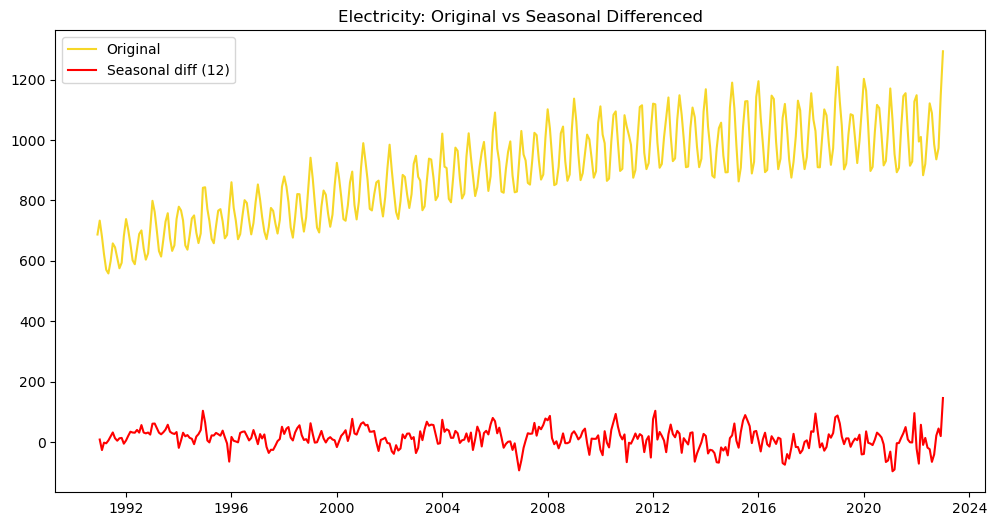

In [62]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Electricity Consumption (MWh)'], label="Original", color='#F6D728')
plt.plot(elec_seasonal_diff, label="Seasonal diff (12)", color='#ff0000')
plt.title("Electricity: Original vs Seasonal Differenced")
plt.legend()
plt.show()


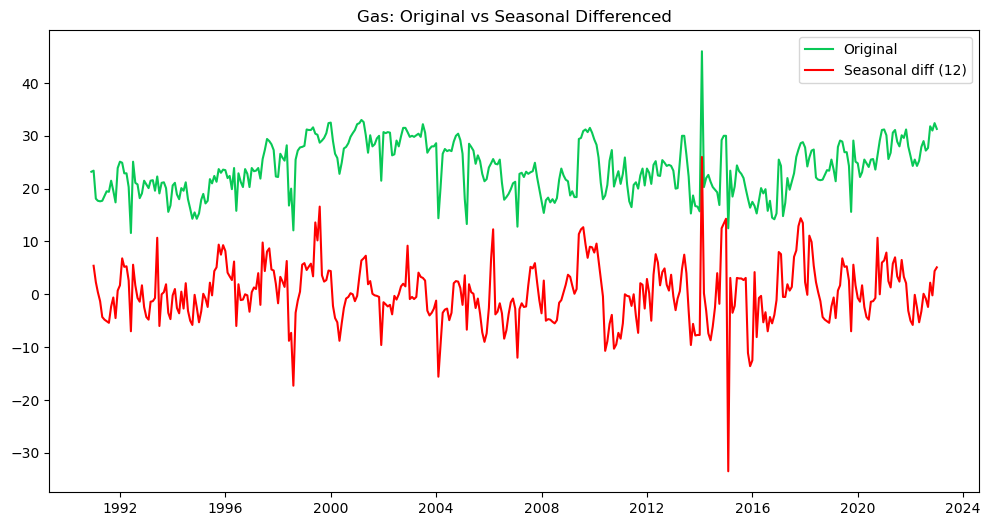

In [64]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Gas Consumption (tons)'], label="Original", color='#09C856')
plt.plot(gas_seasonal_diff, label="Seasonal diff (12)", color='#ff0000')
plt.title("Gas: Original vs Seasonal Differenced")
plt.legend()
plt.show()


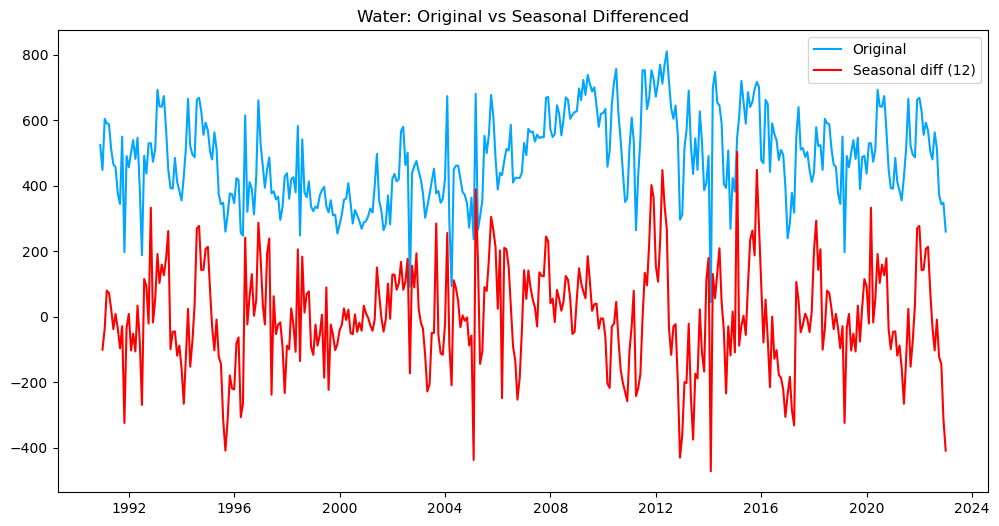

In [65]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Water Consumption (tons)'], label="Original", color='#00A6FF')
plt.plot(water_seasonal_diff, label="Seasonal diff (12)", color='#ff0000')
plt.title("Water: Original vs Seasonal Differenced")
plt.legend()
plt.show()


### **Seasonal Differencing — Electricity, Gas, Water**

To reduce yearly seasonality in this monthly dataset, seasonal differencing is applied using **`.diff(12)`** for each series.

- **Why `diff(12)`?**  
  Because the data is monthly, **12 periods = 12 months = 1 year**.  
  - **`.diff(12)`** computes:  **[y'_t = y_t - y_{t-12}]**
    - This compares each month to the **same month in the previous year**, helping remove repeating annual cycles and making the series more suitable for ACF/PACF and SARIMA-style modelling.

- **Why `dropna()`?**  
  The first **12 rows** become **`NaN`** because there is no earlier year to subtract from (no \(y_{t-12}\)).  
  Dropping them ensures the transformed series contains only valid values for analysis.


### **Step 4.2.1:** ACF & PACF Plotting 

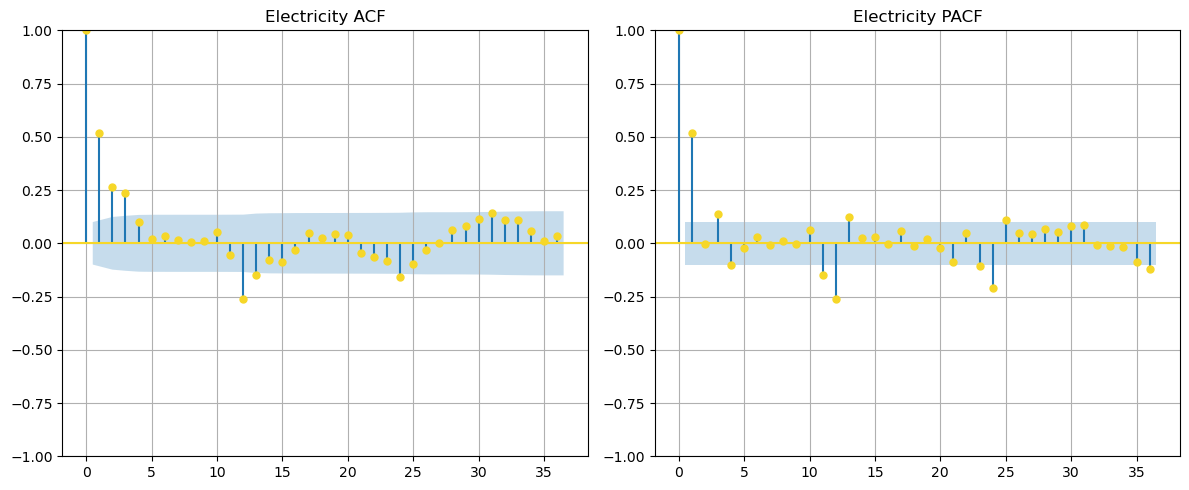

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(elec_seasonal_diff, lags=36, ax=axes[0], color='#F6D728')
axes[0].set_title('Electricity ACF')
axes[0].grid(True)

plot_pacf(elec_seasonal_diff, lags=36, ax=axes[1], method='ywm', color='#F6D728')
axes[1].set_title('Electricity PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

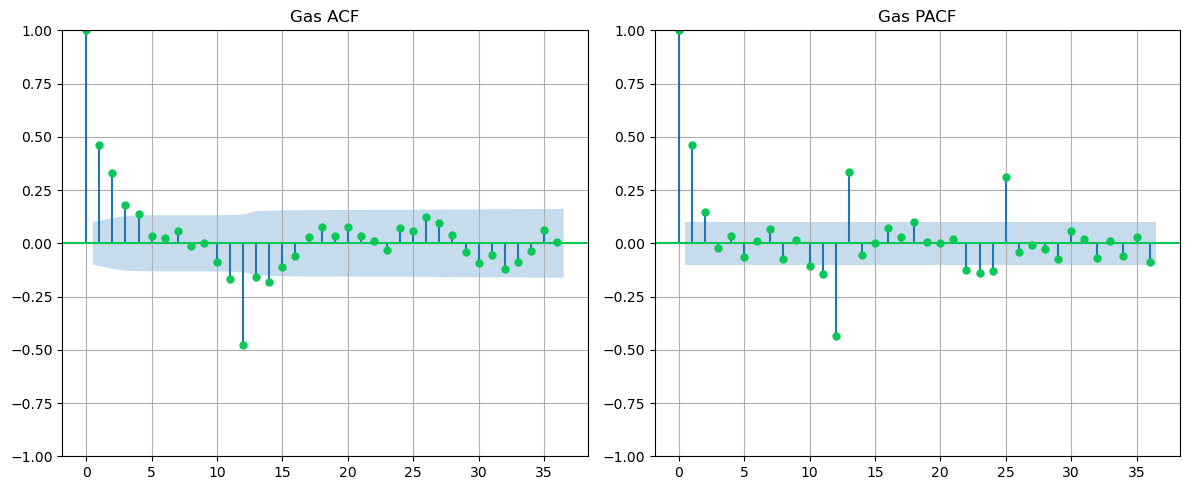

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(gas_seasonal_diff, lags=36, ax=axes[0], color='#09C856')
axes[0].set_title('Gas ACF')
axes[0].grid(True)

plot_pacf(gas_seasonal_diff, lags=36, ax=axes[1], method='ywm', color='#09C856')
axes[1].set_title('Gas PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

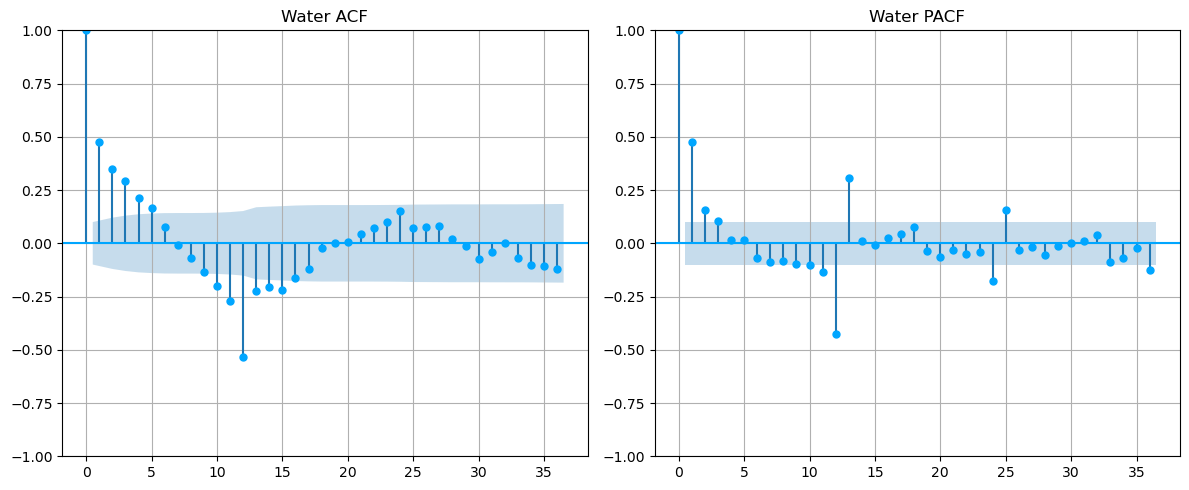

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(water_seasonal_diff, lags=36, ax=axes[0], color='#00A6FF')
axes[0].set_title('Water ACF')
axes[0].grid(True)

plot_pacf(water_seasonal_diff, lags=36, ax=axes[1], method='ywm', color='#00A6FF')
axes[1].set_title('Water PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### **What Can Be Observed:**

## **Step 4.3:** Feature Engineering
- New Columns will be added.
- Implement Simple Moving Average, and store values in 2 separate columns.

In [50]:
energy_df['Water_To_Gas_Ratio'] = round((energy_df['Water Consumption (tons)'] / energy_df['Gas Consumption (tons)']), 2)
energy_df['Water_Gas_Diff (tons)'] = energy_df['Water Consumption (tons)'] - energy_df['Gas Consumption (tons)']
energy_df['Water_Amount (%)'] = (energy_df['Water Consumption (tons)'] / (energy_df['Water Consumption (tons)'] + energy_df['Gas Consumption (tons)']) * 100)
energy_df

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons),Water_To_Gas_Ratio,Water_Gas_Diff (tons),Water_Amount (%)
DATE,,,,,,
1990-01-01,18.0,725.1,548.8,30.49,530.8,96.824277
1990-02-01,15.8,706.7,640.7,40.55,624.9,97.593298
1990-03-01,17.3,624.5,511.1,29.54,493.8,96.725965
1990-04-01,18.9,574.7,515.3,27.26,496.4,96.461999
1990-05-01,22.0,553.2,488.4,22.20,466.4,95.689655
...,...,...,...,...,...,...
2022-09-01,27.7,986.2,513.3,18.53,485.6,94.879852
2022-10-01,31.8,936.1,373.1,11.73,341.3,92.146209
2022-11-01,31.0,973.4,343.9,11.09,312.9,91.731128


- Simple columns were added to compare the usages between gas and water due to their common units.
    - **`'Water_To_Gas_Ratio'`** is the ratio between water and gas consumption, it shows how many more times water is used than gas per month.
    
    - **`'Water_Gas_Diff'`** is the difference between water and gas consumption, instead of showing more times water is used, it shows how much more water is used per month than gas.
    
    - **`'Water_Amount'`** is the percentage of water used from the total amount of gas and water consumed per month.


In [51]:

energy_df['Gas_SMA_6'] = energy_df['Gas Consumption (tons)'].rolling(window=6).mean()
energy_df['Gas_SMA_12'] = energy_df['Gas Consumption (tons)'].rolling(window=12).mean()

energy_df['Electricity_SMA_6'] = energy_df['Electricity Consumption (MWh)'].rolling(window=6).mean()
energy_df['Electricity_SMA_12'] = energy_df['Electricity Consumption (MWh)'].rolling(window=12).mean()

energy_df['Water_SMA_6'] = energy_df['Water Consumption (tons)'].rolling(window=6).mean()
energy_df['Water_SMA_12'] = energy_df['Water Consumption (tons)'].rolling(window=12).mean()




print(f"Dataset {energy_df}")
energy_df = energy_df.dropna()
energy_df.head(20)

Dataset             Gas Consumption (tons)  Electricity Consumption (MWh)  \
DATE                                                                
1990-01-01                    18.0                          725.1   
1990-02-01                    15.8                          706.7   
1990-03-01                    17.3                          624.5   
1990-04-01                    18.9                          574.7   
1990-05-01                    22.0                          553.2   
...                            ...                            ...   
2022-09-01                    27.7                          986.2   
2022-10-01                    31.8                          936.1   
2022-11-01                    31.0                          973.4   
2022-12-01                    32.4                         1147.2   
2023-01-01                    31.3                         1294.0   

            Water Consumption (tons)  Water_To_Gas_Ratio  \
DATE                              

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons),Water_To_Gas_Ratio,Water_Gas_Diff (tons),Water_Amount (%),Gas_SMA_6,Gas_SMA_12,Electricity_SMA_6,Electricity_SMA_12,Water_SMA_6,Water_SMA_12
DATE,,,,,,,,,,,,
1990-12-01,23.2,687.1,524.4,22.60,501.2,95.763331,23.083333,21.158333,615.800000,621.658333,487.650000,511.116667
1991-01-01,23.4,733.1,448.4,19.16,425.0,95.040271,22.883333,21.608333,633.616667,622.325000,487.666667,502.750000
1991-02-01,18.1,679.9,604.7,33.41,586.6,97.093770,21.766667,21.800000,641.516667,620.091667,519.833333,499.750000
1991-03-01,17.7,622.2,591.0,33.39,573.3,97.092164,20.750000,21.833333,644.250000,619.900000,544.866667,506.408333
1991-04-01,17.6,570.3,588.0,33.41,570.4,97.093791,20.316667,21.725000,645.433333,619.533333,546.366667,512.466667
1991-05-01,17.7,558.1,513.0,28.98,495.3,96.664782,19.616667,21.366667,641.783333,619.941667,544.916667,514.516667
1991-06-01,18.6,599.0,465.5,25.03,446.9,96.157819,18.850000,20.966667,627.100000,621.450000,535.100000,511.375000
1991-07-01,19.5,657.7,457.3,23.45,437.8,95.910235,18.200000,20.541667,614.533333,624.075000,536.583333,512.125000
1991-08-01,19.4,644.8,376.5,19.41,357.1,95.099773,18.416667,20.091667,608.683333,625.100000,498.550000,509.191667


Implemented 6 new columns using the Simple Moving Average (SMA) with windows of 6 and 12.
- Why 6 and 12?
    - I used 6 because it represents taking the half-year moving average.
    - Likewise for 12, it represents taking full-year moving average.

- After that, I dropped the rows whose SMA 6 and 12 Score was NaN.
- Although dropping them means losing data, I feel that it is still acceptable just because of the fact that the rows that were dropped were from 1990, which is the very first year featured in this dataset.
    - I think that since it is the first year, the data represented would be the oldest, and realistically, the energy consumption has evolved throughout the years and more and more energy is being consumed as time flies. Hence, I think the data represented by 1990 is too old and unreliable, hence it might not be meaningful in making useful predictions in the average of future years. Therefore, I am dropping them.

In [52]:
print("Preprocessing and Feature Engineering Complete!")

print("\nAfter Feature Engineering, here are the present columns in the DataFrame: \n", energy_df.columns)

print(f"\nAnd Here is the shape of the Dataset: {energy_df.shape}")


Preprocessing and Feature Engineering Complete!

After Feature Engineering, here are the present columns in the DataFrame: 
 Index(['Gas Consumption (tons)', 'Electricity Consumption (MWh)',
       'Water Consumption (tons)', 'Water_To_Gas_Ratio',
       'Water_Gas_Diff (tons)', 'Water_Amount (%)', 'Gas_SMA_6', 'Gas_SMA_12',
       'Electricity_SMA_6', 'Electricity_SMA_12', 'Water_SMA_6',
       'Water_SMA_12'],
      dtype='object')

And Here is the shape of the Dataset: (386, 12)


In [53]:
len(energy_df)

386

- Printing out all the columns in the DataFrame shows all the columns, included those that were added.
- The shape of the new DataFrame was added, showing that it has a shape of (386, 12), indicating that the DataFrame has 386 rows and 12 columns.

---
## **Step 5:** Model Implementation & Analysis
In this section, we are going to implement different models into the dataset and analyse their results.

### **Step 5.1:** ACF and PACF
- This is done to find the 'p' and 'q' values for the ARIMA models.

### **Step 5.2:** Train-Test Split
- Split the data into 2 parts, a training set and a test set.

In [54]:
n = len(energy_df)

train = energy_df.iloc[:int(n * 0.7)]
test = energy_df.iloc[int(n * 0.7):]

### **Some Insights:**
- Splitting the Data into 3 parts, with train holding the highest weightage of 70% of the data in the dataset, while both val and test data hold the weightage of 15% each.

- **train:**    
    - **`'energy_df.iloc[:int(n * 0.7)]'`** means returning the very first row until the 270th row (70% x 386 = 270), thus it gives **`rows 0 - 269.`**

- **val:**
    - **`energy_df.iloc[int(n * 0.7):int(n * 0.85)]`** means returning the row that we ended with on train, which is the 270th row, up till the 328th row (85% x 386 = 328), thus it gives **`rows 270-327`**.

- **test:**
    - **`'energy_df.iloc[int(n * 0.85):]'`** means returning the rows that start from the 85th percentile (Row 328) till the end. Essentially returning **`row 328 - 385`**.



### **Why a 70–15–15 Split Was Chosen:**

- A **`70–15–15`** train–validation–test split was selected as a balanced compromise for this time-series dataset.

- The training set requires a sufficiently long historical window to allow ARIMA-based models to learn long-term trends, seasonal patterns, and autocorrelation structures in energy consumption. Using 70% of the data ensures model stability and robust parameter estimation.

- A dedicated validation set (15%) is included to support hyperparameter tuning and feature comparison (e.g., SMA-6 vs SMA-12) without contaminating the final evaluation. This prevents overfitting by ensuring that model design decisions are not influenced by future data.

- The final 15% test set is reserved for unbiased performance assessment on the most recent energy consumption behaviour, providing a realistic measure of real-world forecasting accuracy.

- Alternative splits such as 80–10-10 were avoided due to insufficient validation data for reliable tuning, while 60-20-20 or 50–25-25 splits were avoided because they reduce training dataset, making it too small which can weaken long-term pattern learning, leading to potential underfitting. The 70–15–15 split therefore provides a practical balance between learning capacity and evaluation reliability for this dataset.

In [55]:
print("Total rows:", len(energy_df))

print("\nTrain set:")
print("Rows:", len(train))
print("Start:", train.index.min())
print("End:", train.index.max())



print("\nTest set:")
print("Rows:", len(test))
print("Start:", test.index.min())
print("End:", test.index.max())

Total rows: 386

Train set:
Rows: 270
Start: 1990-12-01 00:00:00
End: 2013-05-01 00:00:00

Test set:
Rows: 116
Start: 2013-06-01 00:00:00
End: 2023-01-01 00:00:00


### Key Insights (Train–Validation–Test Split)

- The dataset is split chronologically into three parts: a training set (1990–2013, 270 rows), a validation set (2013–2018, 58 rows), and a test set (2018–2023, 58 rows). This preserves temporal order and prevents future data leakage.

- The training set provides sufficient historical data for the models to learn long-term trends and seasonality in energy consumption. The validation set is used for tuning model parameters and comparing feature configurations (e.g., SMA-6 vs SMA-12) without influencing final performance. The test set is reserved for final evaluation only, ensuring an unbiased assessment on recent energy consumption patterns.

- A 70–15–15 split is chosen as a balanced trade-off for this relatively small dataset, offering stable model learning while maintaining enough unseen data for fair tuning and realistic forecasting evaluation.



### **Split Train, Validation & Test Datasets Into Respective Energy Sources:**

In [56]:
elec_train, elec_val = train['Electricity Consumption (MWh)'], val['Electricity Consumption (MWh)']
gas_train, gas_val = train['Gas Consumption (tons)'], val['Gas Consumption (tons)']
water_train, water_val = train['Water Consumption (tons)'], val['Water Consumption (tons)']

NameError: name 'val' is not defined

Insights

### **Step 5.2:** Model Fitting - **ARIMA**

In [ ]:
elec_arima = ARIMA(elec_train, order=(1, 1, 1)).fit()
gas_arima = ARIMA(gas_train, order=(1, 0, 1)).fit()
water_arima = ARIMA(water_train, order=(1, 0, 1)).fit()

elec_pred = elec_arima.forecast(steps=len(elec_val))
gas_pred = gas_arima.forecast(steps=len(gas_val))
water_pred = water_arima.forecast(steps=len(water_val))

c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

- ARIMA models were first fitted to each consumption series using orders selected based on stationarity tests and autocorrelation patterns. 
- Electricity uses differencing (d=1) due to its non-stationary origin, in order to remove trend effects , while gas and water use d=0 as they are already stationary.

### **Step 5.3:** Model Fitting - **SARIMA**
- SARIMA is ARIMA + Seasonality.



In [ ]:
elec_sarima = SARIMAX(elec_train, 
                      order=(1, 1, 1),
                      seasonal_order=(1, 1, 1, 12),
                      enforce_stationarity=False,
                      enforce_invertibility=False
                      ).fit(disp=False)
gas_sarima = SARIMAX(gas_train, 
                      order=(1, 0, 1),
                      seasonal_order=(1, 0, 1, 12),
                      enforce_stationarity=False,
                      enforce_invertibility=False
                      ).fit(disp=False)
water_sarima = SARIMAX(water_train, 
                      order=(1, 0, 1),
                      seasonal_order=(1, 0, 1, 12),
                      enforce_stationarity=False,
                      enforce_invertibility=False
                      ).fit(disp=False)



c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\nedya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

- SARIMAX models are implemented separately for electricity, gas, and water to capture both trend and seasonal dynamics in each energy series.

- SARIMAX extends ARIMA by adding seasonal awareness, allowing the model to learn repeating consumption patterns such as yearly or monthly cycles that are common in energy usage.

- ### **Parameters used:**
    - **`'seasonal_order'`** is taking the orginal order with the addition of the number of periods per cycle, in this case, its 12, which represents a 12-month seasonal cycle.
        - Taking the trend every 12-months/year.
    
    - **`'enforce_stationarity=False'`** allows the model to estimate parameters even if AR part is non-stationary.

    - **`'enforce_invertibility=False'`** allows the MA part of the model to estimate freely even if it violates strict invertibility conditions.

    - **`'.fit(disp=False)'`** fits the model quietly

### **Step 5.4:** Model Fitting - **Auto-ARIMA**

In [ ]:
elec_aarima = auto_arima(elec_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=1.16 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=3045.199, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=inf, Time=0.28 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=2814.858, Time=0.20 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=3043.239, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=2966.865, Time=0.07 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=2647.012, Time=0.55 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=2579.699, Time=0.33 sec
 ARIMA(0,1,1)(2,0,0)[12] intercept   : AIC=2540.725, Time=1.09 sec
 ARIMA(0,1,1)(2,0,1)[12] intercept   : AIC=2740.238, Time=0.64 sec
 ARIMA(0,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=0.74 sec
 ARIMA(1,1,1)(2,0,0)[12] intercept   : AIC=inf, Time=2.08 sec
 ARIMA(0,1,2)(2,0,0)[12] intercept   : AIC=inf, Time=4.31 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=1.44 sec
 ARIMA(1,1,2)(2,0,0)[12] intercept   : AIC=inf, T

In [ ]:
gas_aarima = auto_arima(gas_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=1367.853, Time=0.87 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1401.215, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1389.179, Time=0.10 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1382.413, Time=0.10 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1399.231, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=1366.763, Time=0.52 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=1365.597, Time=0.13 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=1366.625, Time=0.57 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=1363.656, Time=0.12 sec
 ARIMA(1,1,2)(1,0,0)[12] intercept   : AIC=1364.711, Time=0.28 sec
 ARIMA(1,1,2)(0,0,1)[12] intercept   : AIC=1364.848, Time=0.32 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=1365.930, Time=0.71 sec
 ARIMA(0,1,2)(0,0,0)[12] intercept   : AIC=1373.074, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=1361.757, Time=0.10 sec
 ARIMA(1,1,1)(1,0,0

In [ ]:
water_aarima = auto_arima(water_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=3242.768, Time=1.08 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=3306.500, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=3280.333, Time=0.10 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=3257.096, Time=0.29 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=3304.500, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=3245.350, Time=0.72 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=3245.350, Time=0.75 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=3242.110, Time=2.40 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=3240.165, Time=2.14 sec
 ARIMA(1,1,2)(2,0,0)[12] intercept   : AIC=3238.936, Time=1.24 sec
 ARIMA(1,1,2)(1,0,0)[12] intercept   : AIC=3243.342, Time=0.37 sec
 ARIMA(1,1,2)(2,0,1)[12] intercept   : AIC=3240.608, Time=1.72 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=3243.004, Time=0.82 sec
 ARIMA(0,1,2)(2,0,0)[12] intercept   : AIC=3242.504, Time=0.77 sec
 ARIMA(1,1,1)(2,0,0

- Auto-ARIMA is applied separately to electricity, gas, and water using the training set only to avoid data leakage.

- Auto-ARIMA automatically searches through multiple ARIMA configurations and selects the best-performing model, reducing manual trial-and-error and ensuring a more objective choice of parameters.

- ### **Parameters Used:**
    - **`'seasonal=True'`** enables SARIMA-style seasonal search.

    - **`'m=12'`** represents a 12 month seasonal cycle.

    - **`'stepwise=True'`** enables faster and smarter parameter search.
    
    - **`'trace=True'`** shows what models are being tested.

    - **`'suppress_warnings=True'`** hides harmless warnings.

    - **`'error_action="ignore"'`** skips failed model configs.


- ### **Results:**
    - Auto-ARIMA selected ARIMA(1,1,2)(1,0,1)[12] as the best ARIMA model for electricity consumption, suggesting the series requires differencing (`d=1`) and contains yearly seasonal behaviour (`m=12`).
    
    - Auto-ARIMA selected  ARIMA(1,1,1)(0,0,0)[12] as the best ARIMA model for gas consumption, indicating differencing is useful but seasonal terms are not strongly needed.

    - Auto-ARIMA selected ARIMA(1,1,1)(2,0,0)[12] as the best ARIMA model for water consumption, indicating differencing is useful and some seasonal structure exists (seasonal AR terms).


- **Note:**
    - Despite ADF test shows that both gas and water consumption are stationary, d=1 is included in the order of auto-ARIMA as it optimises AIC scores and sometimes picks differencing if it helps improve the overall AIC score and forecastin performance.

Overall, the selected models provide a data-driven benchmark to compare against ARIMA & SARIMAX settings using validation MAE/RMSE as well as AIC & BIC.

### **Step 5.5:** Holt Winter

## **Step 5.6:** ACF and PACF
- This is done to find the 'p' and 'q' values for the ARIMA models.

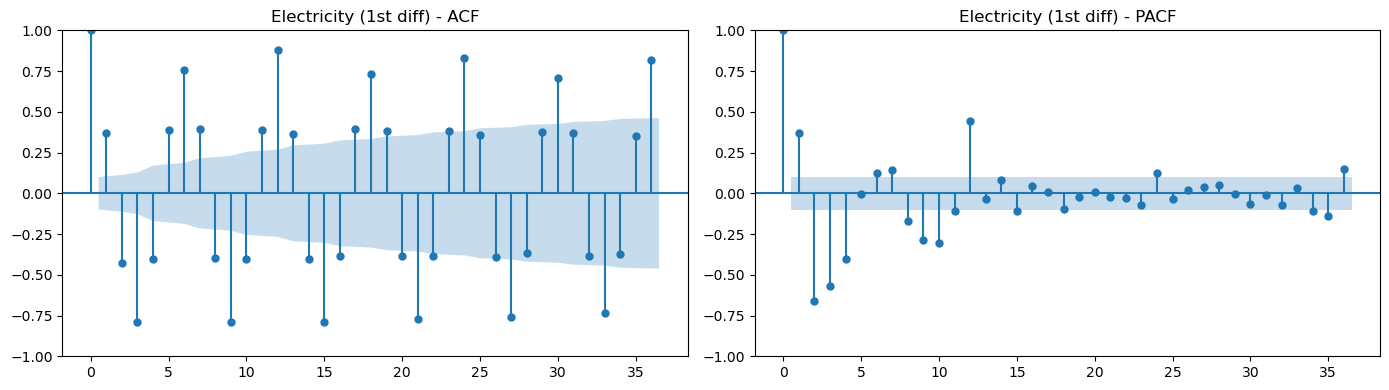

In [ ]:
elec_diff = energy_df['Electricity Consumption (MWh)'].diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(elec_diff, lags=36, ax=axes[0])
axes[0].set_title("Electricity (1st diff) - ACF")

plot_pacf(elec_diff, lags=36, ax=axes[1], method="ywm")
axes[1].set_title("Electricity (1st diff) - PACF")

plt.tight_layout()
plt.show()

---
## **Step 6:** Model Evaluation
In this section, we are going to evaluate the performance of each model by comparing their AIC, BIC scores, and error management (MAE, RMSE).

Chose 1 model out of the 3 that yields the best results and that model will be our finalised model.

### **Step 6.1:** Evaluation Using Mean Absolute Error **(MAE)** & Root Mean Squared Error **(RMSE)**


#### **Step 6.1.1:** ARIMA 

In [ ]:
elec_arima_forecast = elec_arima.forecast(steps=len(val))

elec_arima_mae = mean_absolute_error(elec_val, elec_arima_forecast)
elec_arima_rmse = root_mean_squared_error(elec_val, elec_arima_forecast)

print("Electricity Consumption ARIMA MAE:", round(elec_arima_mae, 2), "\nElectricity Consumption ARIMA RMSE:", round(elec_arima_rmse, 2))

gas_arima_forecast = gas_arima.forecast(steps=len(val))

gas_arima_mae = mean_absolute_error(gas_val, gas_arima_forecast)
gas_arima_rmse = root_mean_squared_error(gas_val, gas_arima_forecast)

print("\nGas Consumption ARIMA MAE:", round(gas_arima_mae, 2), "\nGas Consumption ARIMA RMSE:", round(gas_arima_rmse, 2))


water_arima_forecast = water_arima.forecast(steps=len(val))

water_arima_mae = mean_absolute_error(water_val, water_arima_forecast)
water_arima_rmse = root_mean_squared_error(water_val, water_arima_forecast)

print("\nWater Consumption ARIMA MAE:", round(water_arima_mae, 2), "\nWater Consumption ARIMA RMSE:", round(water_arima_rmse, 2))




Electricity Consumption ARIMA MAE: 97.78 
Electricity Consumption ARIMA RMSE: 120.96

Gas Consumption ARIMA MAE: 5.15 
Gas Consumption ARIMA RMSE: 6.28

Water Consumption ARIMA MAE: 111.59 
Water Consumption ARIMA RMSE: 140.8


#### **Step 6.1.2:** SARIMAX

In [ ]:
elec_sarima_forecast = elec_sarima.forecast(steps=len(val))

elec_sarima_mae = mean_absolute_error(elec_val, elec_sarima_forecast)
elec_sarima_rmse = root_mean_squared_error(elec_val, elec_sarima_forecast)

print("Electricity Consumption SARIMA MAE:", round(elec_sarima_mae, 2), "\nElectricity Consumption SARIMA RMSE:", round(elec_sarima_rmse, 2))


gas_sarima_forecast = gas_sarima.forecast(steps=len(val))

gas_sarima_mae = mean_absolute_error(gas_val, gas_sarima_forecast)
gas_sarima_rmse = root_mean_squared_error(gas_val, gas_sarima_forecast)

print("\nGas Consumption SARIMA MAE:", round(gas_sarima_mae, 2), "\nGas Consumption SARIMA RMSE:", round(gas_sarima_rmse, 2))


water_sarima_forecast = water_sarima.forecast(steps=len(val))

water_sarima_mae = mean_absolute_error(water_val, water_sarima_forecast)
water_sarima_rmse = root_mean_squared_error(water_val, water_sarima_forecast)

print("\nWater Consumption SARIMA MAE:", round(water_sarima_mae, 2), "\nWater Consumption SARIMA RMSE:", round(water_sarima_rmse, 2))




Electricity Consumption SARIMA MAE: 61.87 
Electricity Consumption SARIMA RMSE: 70.91

Gas Consumption SARIMA MAE: 5.99 
Gas Consumption SARIMA RMSE: 6.99

Water Consumption SARIMA MAE: 110.18 
Water Consumption SARIMA RMSE: 138.46


#### **Step 6.1.3:** Auto-ARIMA

In [ ]:
elec_aarima_forecast = elec_aarima.predict(n_periods=len(val))

elec_aarima_mae = mean_absolute_error(elec_val, elec_aarima_forecast)
elec_aarima_rmse = root_mean_squared_error(elec_val, elec_aarima_forecast)

print("Electricity Consumption Auto-ARIMA MAE:", round(elec_aarima_mae, 2), "\nElectricity Consumption Auto-ARIMA RMSE:", round(elec_aarima_rmse, 2))


gas_aarima_forecast = gas_aarima.predict(n_periods=len(val))

gas_aarima_mae = mean_absolute_error(gas_val, gas_aarima_forecast)
gas_aarima_rmse = root_mean_squared_error(gas_val, gas_aarima_forecast)

print("\nGas Consumption Auto-ARIMA MAE:", round(gas_aarima_mae, 2), "\nGas Consumption Auto-ARIMA RMSE:", round(gas_aarima_rmse, 2))


water_aarima_forecast = water_aarima.predict(n_periods=len(val))

water_aarima_mae = mean_absolute_error(water_val, water_aarima_forecast)
water_aarima_rmse = root_mean_squared_error(water_val, water_aarima_forecast)

print("\nWater Consumption Auto-ARIMA MAE:", round(water_aarima_mae, 2), "\nWater Consumption Auto-ARIMA RMSE:", round(water_aarima_rmse, 2))

Electricity Consumption Auto-ARIMA MAE: 55.19 
Electricity Consumption Auto-ARIMA RMSE: 63.39

Gas Consumption Auto-ARIMA MAE: 5.18 
Gas Consumption Auto-ARIMA RMSE: 6.34

Water Consumption Auto-ARIMA MAE: 122.69 
Water Consumption Auto-ARIMA RMSE: 158.31


In [ ]:
mae_rmse_results = pd.DataFrame({
        "Energy": ['Electricity',
                     'Electricity',
                      'Electricity',
                       'Gas',
                        'Gas',
                          'Gas',
                            'Water',
                              'Water',
                                'Water'
                                ],
        "Model": ["ARIMA",
                   "SARIMAX",
                     "AUTO-ARIMA",
                       "ARIMA",
                         "SARIMAX",
                           "AUTO-ARIMA",
                             "ARIMA",
                               "SARIMAX",
                                 "AUTO-ARIMA"
                                 ],
        "MAE": [elec_arima_mae,
                 elec_sarima_mae,
                   elec_aarima_mae,
                     gas_arima_mae,
                       gas_sarima_mae,
                         gas_aarima_mae,
                           water_arima_mae,
                             water_sarima_mae,
                               water_aarima_mae
                               ],
        "RMSE": [elec_arima_rmse,
                  elec_sarima_rmse, 
                  elec_aarima_rmse, 
                  gas_arima_rmse, 
                  gas_sarima_rmse, 
                  gas_aarima_rmse, 
                  water_arima_rmse, 
                  water_sarima_rmse, 
                  water_aarima_rmse]
                  })


mae_rmse_results

,Energy,Model,MAE,RMSE
0,Electricity,ARIMA,97.784924,120.956954
1,Electricity,SARIMAX,61.866079,70.908050
2,Electricity,AUTO-ARIMA,55.187584,63.394483
3,Gas,ARIMA,5.147515,6.282262
4,Gas,SARIMAX,5.992302,6.991860
5,Gas,AUTO-ARIMA,5.176343,6.344020
6,Water,ARIMA,111.589592,140.800878
7,Water,SARIMAX,110.175874,138.464414
8,Water,AUTO-ARIMA,122.694405,158.313363


### **Justification for MAE and RMSE:**

MAE and RMSE are used jointly to evaluate forecasting performance because they capture complementary error behaviours.

- MAE measures the average absolute deviation between predicted and actual values, providing an intuitive and robust estimate of typical forecast error in the same unit as the data.
- RMSE squares the error before averaging, thereby penalising large forecasting errors more heavily. This is particularly important for electricity consumption, where large deviations can lead to operational and planning risks.

Using both metrics ensures a balanced assessment: MAE reflects general prediction accuracy, while RMSE highlights sensitivity to large forecast misses. This dual-metric approach prevents misleading conclusions that may arise from relying on a single error measure.

### **Step 6.2:** **AIC/BIC** Comparison

In [ ]:
aic_bic_results = pd.DataFrame({
    "Energy Types": ['Electricity', 'Gas', 'Water'],
    "ARIMA_AIC": [elec_arima.aic,
                  gas_arima.aic,
                  water_arima.aic
                  ],
    "ARIMA_BIC": [elec_arima.bic,
                  gas_arima.bic,
                  water_arima.bic
                  ],
    "SARIMAX_AIC": [elec_sarima.aic,
                    gas_sarima.aic,
                    water_sarima.aic
                    ],
    "SARIMAX_BIC": [elec_sarima.bic,
                    gas_sarima.bic,
                    water_sarima.bic
                    ],
    "AUTO-ARIMA_AIC":[elec_aarima.aic(),
                      gas_aarima.aic(),
                      water_aarima.aic()
                      ],
    "AUTO-ARIMA_BIC": [elec_aarima.bic(),
                      gas_aarima.bic(),
                      water_aarima.bic()
                      ]

})

aic_bic_results

,Energy Types,ARIMA_AIC,ARIMA_BIC,SARIMAX_AIC,SARIMAX_BIC,AUTO-ARIMA_AIC,AUTO-ARIMA_BIC
0,Electricity,2966.637908,2977.422042,2193.933502,2211.398810,2447.149750,2468.718018
1,Gas,1372.342664,1386.736352,1320.167079,1337.892966,1359.909674,1370.693808
2,Water,3258.501263,3272.894951,3095.683995,3113.409883,3235.597764,3253.571321


### Key Insights (Model Evaluation – Validation Set)

- Model performance is first evaluated using MAE and RMSE on the validation set to assess real-world forecasting accuracy.
- For electricity, the model with the lower RMSE is prioritised due to the strong upward trend and higher sensitivity to large errors.
- For gas and water, MAE is considered alongside RMSE to balance robustness against volatility and outliers.

- AIC and BIC are then used as secondary criteria to assess model complexity and goodness of fit.
- While Auto-ARIMA often achieves lower AIC due to data-driven tuning, the final model selection prioritises validation RMSE to avoid overfitting.

- The final forecasting model for each energy series is selected based on a combination of:
  (i) lowest validation RMSE,  
  (ii) competitive MAE, and  
  (iii) reasonable AIC/BIC values indicating stable model complexity.

### Comparison with SMA:

---
## **Step 7:** Model Improvement **(Hyperparameter Tuning)**

Implement hyperparameter tuning to the selected model in order to obtain the best parameters that can achieve the most optimal results and predictions.

--- 
## **Summary of Part B:**